In [2]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt, pathlib, json
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file("flower_photos.tar", origin=url, extract=True)
data_dir = pathlib.Path(data_dir).with_suffix("")
IMG, BATCH = (160, 160), 32
for c in sorted(p.name for p in data_dir.iterdir() if p.is_dir()):
    print(c, len(list((data_dir/c).glob("*.jpg"))))

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
flower_photos 0


In [4]:
if (data_dir / "flower_photos").exists():
    data_dir = data_dir / "flower_photos"

for c in sorted(p.name for p in data_dir.iterdir() if p.is_dir()):
    print(c, len(list((data_dir / c).glob("*.jpg"))))

daisy 633
dandelion 898
roses 641
sunflowers 699
tulips 799


In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.3, subset="training", seed=42, image_size=IMG, batch_size=BATCH)
rest_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.3, subset="validation", seed=42, image_size=IMG, batch_size=BATCH)
class_names = train_ds.class_names

# Se recorre UNA sola vez para que validación y prueba queden fijas
xs, ys = [], []
for x, y in rest_ds:
    xs.append(x.numpy()); ys.append(y.numpy())
X, Y = np.concatenate(xs), np.concatenate(ys)
half = len(X) // 2
X_val, Y_val, X_test, Y_test = X[:half], Y[:half], X[half:], Y[half:]
print(class_names, X_val.shape, X_test.shape)

Found 3670 files belonging to 5 classes.
Using 2569 files for training.
Found 3670 files belonging to 5 classes.
Using 1101 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] (550, 160, 160, 3) (551, 160, 160, 3)


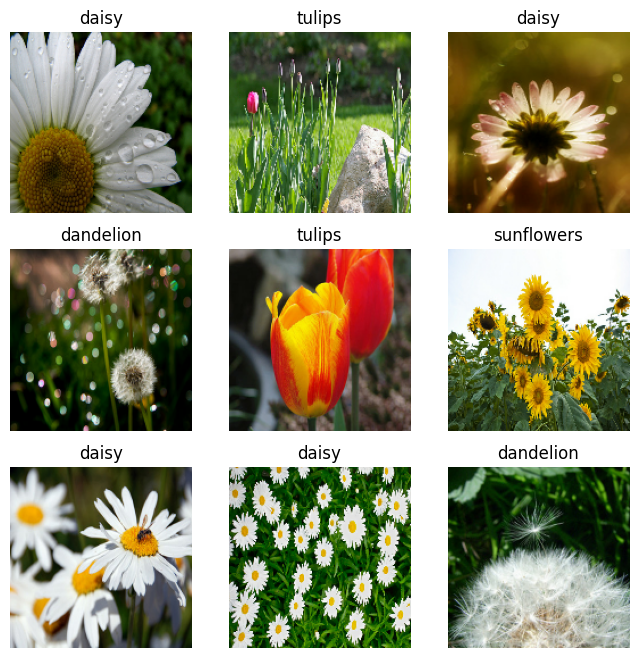

In [6]:
plt.figure(figsize=(8, 8))
for x, y in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(x[i].numpy().astype("uint8"))
        plt.title(class_names[y[i]]); plt.axis("off")
plt.show()

In [7]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.1), layers.RandomZoom(0.1)
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=IMG + (3,)),
    augment,
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Dropout(0.3), layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_names), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,437 (20.61 MB)

 Trainable params: 5,402,437 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
train_p = train_ds.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)
es = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True)
history = model.fit(train_p, validation_data=(X_val, Y_val), epochs=25, callbacks=[es])

Epoch 1/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 59ms/step - accuracy: 0.4469 - loss: 1.3092 - val_accuracy: 0.5673 - val_loss: 1.0640
Epoch 2/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.5928 - loss: 1.0407 - val_accuracy: 0.6418 - val_loss: 0.9810
Epoch 3/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.6388 - loss: 0.9204 - val_accuracy: 0.6545 - val_loss: 0.8984
Epoch 4/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.6765 - loss: 0.8373 - val_accuracy: 0.7018 - val_loss: 0.8315
Epoch 5/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.6886 - loss: 0.8165 - val_accuracy: 0.7291 - val_loss: 0.7516
Epoch 6/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7170 - loss: 0.7478 - val_accuracy: 0.7255 - val_loss: 0.7291
Epoch 7/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7310 - loss: 0.7146 - val_accuracy: 0.7327 - val_loss: 0.7637
Epoch 8/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.7314 - loss: 0.6838 - val_accuracy: 0.7364 - 

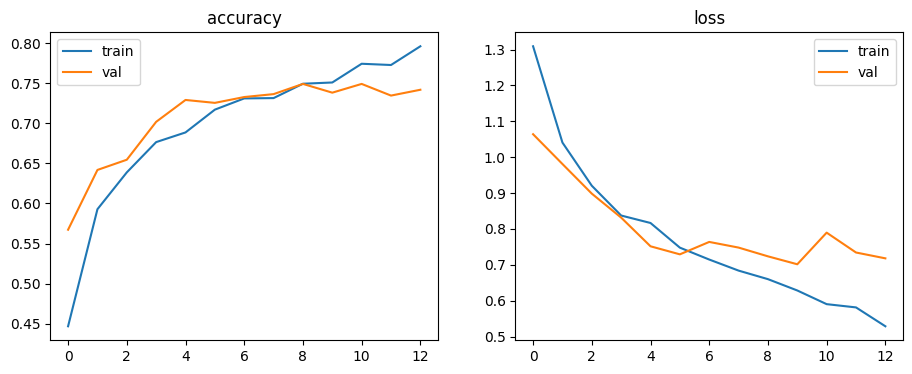

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step
              precision    recall  f1-score   support

       daisy       0.72      0.75      0.73        75
   dandelion       0.78      0.68      0.72       147
       roses       0.49      0.74      0.59        92
  sunflowers       0.75      0.82      0.78        96
      tulips       0.76      0.53      0.62       141

    accuracy                           0.69       551
   macro avg       0.70      0.70      0.69       551
weighted avg       0.71      0.69      0.69       551



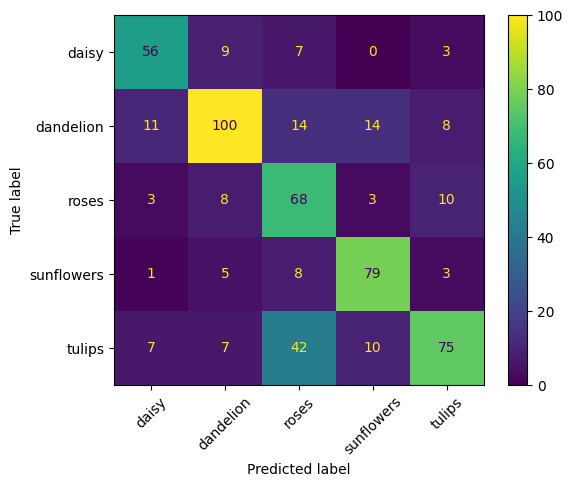

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ["accuracy", "loss"]):
    a.plot(history.history[m], label="train")
    a.plot(history.history["val_"+m], label="val")
    a.set_title(m); a.legend()
plt.show()

probs = model.predict(X_test); y_pred = probs.argmax(1)
print(classification_report(Y_test, y_pred, target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(Y_test, y_pred), display_labels=class_names).plot(xticks_rotation=45)
plt.show()

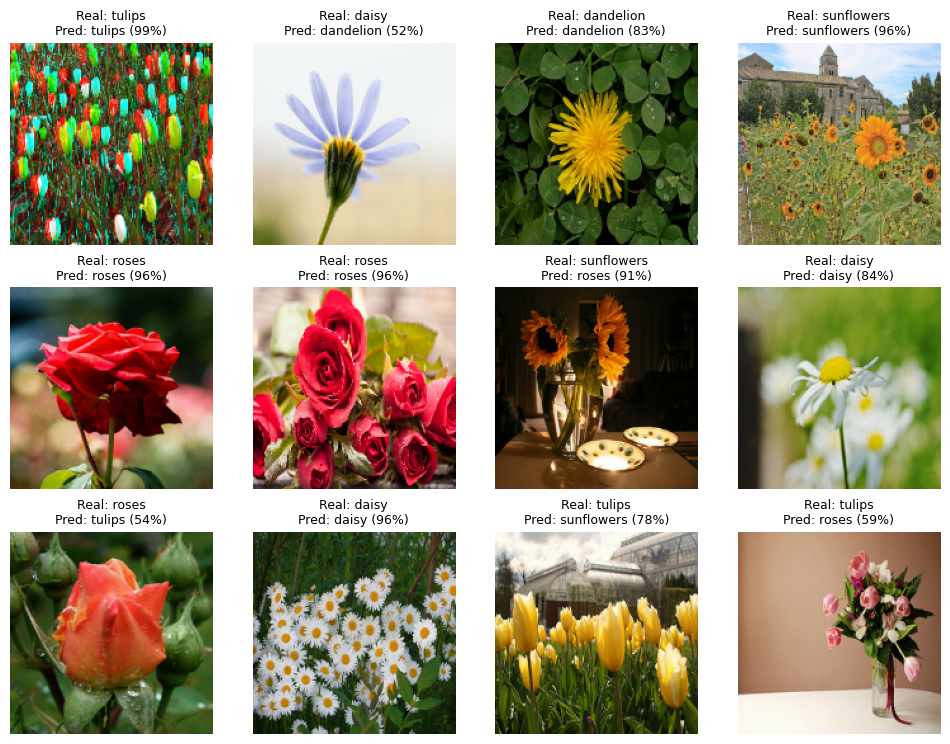

In [10]:
plt.figure(figsize=(12, 9))
for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.imshow(X_test[i].astype("uint8")); plt.axis("off")
    plt.title(f"Real: {class_names[Y_test[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i].max():.0%})", fontsize=9)
plt.show()

In [11]:
model.save("flowers_cnn.keras")
json.dump(class_names, open("class_names.json", "w"))
from google.colab import files
files.download("flowers_cnn.keras"); files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>